# Parallel execution — comparing translation candidates

[Open Colab](https://colab.research.google.com/) and choose **File → Upload notebook** to open this English copy.

**Audience** — Developers new to agents who are familiar with Python functions and async/await.

**Learning objective** — Build a workflow that generates three translations concurrently, collects the results, and selects the best candidate.

**Sequence** — Set up the environment, define inputs and agents, run the workflow, check the results, then try an exercise.

[Source code](../src/main.py) · [Example guide](../README.md) · [Environment setup](../../../../../docs/setup.md)

### Pattern architecture

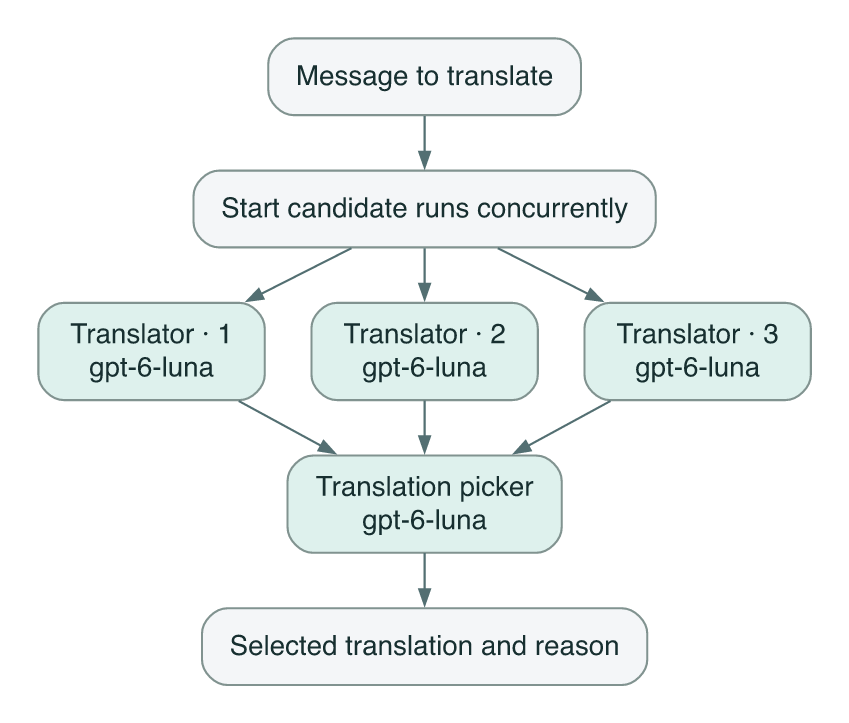

### From diagram to code

| Diagram element | Implementation | Role |
| --- | --- | --- |
| User Query | `message` | Source text to translate |
| Task Allocator | List comprehension and `asyncio.gather()` | Distributes the same task across multiple runs |
| Tasks | `Runner.run(translator, ...)` | Generates translation candidates in parallel |
| Accumulator | `picker` | Compares candidates and chooses the best result |
| Output | `best.final_output` | Selected translation and reason for the choice |

#### Execution flow

1. Create `CANDIDATES` coroutines with `Runner.run()`.
2. Run the translation requests concurrently with `asyncio.gather()`.
3. Collect the completed results in `translations`.
4. Have `picker` compare all candidates and select one.

#### How the example implements the diagram

Python code plays the task allocator role shown in the diagram. Tasks 1–3 are independent runs of the same `translator` agent.

## 1. Set up the environment

### Colab

1. In Colab, choose **File → Upload notebook** and select this `.ipynb` file. A CPU runtime is sufficient. You can run it without cloning the repository or mounting Google Drive.
2. The setup cell installs `openai-agents==0.22.1` and `python-dotenv` if needed. If you already imported a different SDK version, restart the runtime and run from the top.
3. For live calls, open **Secrets** (the key icon in the left sidebar), add your existing key as `OPENAI_API_KEY`, and enable access for this notebook. Keep keys out of code cells. Your local `.env.local` file is not copied into Colab.

### Local Jupyter

Install the shared notebook environment with `uv` and select its kernel. Existing environment variables take precedence. If a `.env.local` file exists in the current directory or a parent, the notebook reads additional settings from it. Offline exercises require neither the file nor a key.

### Run settings

The default `RUN_API=False` builds the agents and runs offline exercises without reading Secrets or calling the API. To see live results, set `RUN_API=True` in the next cell and run the following cells in order. Key lookup order is **environment → optional `.env.local` → Colab Secrets**. The notebook never prints or saves key values. Model calls and web searches may incur charges. Jupyter supports top-level `await` in its existing event loop.

The standalone example later in the notebook has its own `run_api=True` argument, independent of `RUN_API`.


In [ ]:
import os
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# Install only in Colab. Local environments use requirements-notebooks.txt.
try:
    import google.colab
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    try:
        dependencies_ready = (
            version("openai-agents") == "0.22.1"
            and version("python-dotenv").split(".")[0] == "1"
        )
    except PackageNotFoundError:
        dependencies_ready = False
    if not dependencies_ready:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet",
            "openai-agents==0.22.1", "python-dotenv>=1,<2",
        ])

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


RUN_API = False  # Set True for the walkthrough's API and web search calls.
MODEL = load_environment(run_api=RUN_API)
set_tracing_disabled(True)
print({"environment": "Colab" if IN_COLAB else "local", "model": MODEL, "api_enabled": RUN_API})


## 2. Define the translator and selection agent

Run independent translation calls in parallel and choose a candidate once all results have arrived.

In [ ]:
import asyncio
import time

translator = Agent(
    name="Spanish translator",
    model=MODEL,
    instructions="Translate the input into Spanish. Return only the translation.",
)

picker = Agent(
    name="Translation picker",
    model=MODEL,
    instructions=(
        "Choose the best Spanish translation. Return the chosen translation "
        "and a short reason."
    ),
)

message = "Good morning! Welcome to our agent workshop."
CANDIDATES = 3

assert 1 <= CANDIDATES <= 5

## 3. Generate and select candidates (API calls)

`asyncio.gather()` returns results in input order. A failed call propagates an error in this example. Recovery from partial failures requires additional handling.

In [ ]:
translations = []
best = None

if RUN_API:
    started = time.perf_counter()
    results = await asyncio.gather(
        *[Runner.run(translator, message, max_turns=2) for _ in range(CANDIDATES)]
    )
    translations = [str(result.final_output) for result in results]
    best = await Runner.run(
        picker,
        f"Original: {message}\nCandidates: {translations}",
        max_turns=2,
    )
    elapsed = time.perf_counter() - started

    for index, value in enumerate(translations, 1):
        print(f"{index}. {value}")

    print("Selected:", best.final_output)
    print(f"Total elapsed time: {elapsed:.1f}s")
else:
    print("API call skipped")

## 4. Check the results

Verify the number of responses and check that each contains text. The same model may produce identical translations.

In [ ]:
if best is not None:
    assert len(translations) == CANDIDATES
    assert all(text.strip() for text in translations)
    assert str(best.final_output).strip()

## 5. Run the workflow as a Python module with `main()`

The preceding cells walk through the workflow step by step. The next cell packages the same workflow as an independent Python module. Once the dependencies are installed, you can start with this cell because it defines its own agents and variables.

The function runs the same translation agent concurrently several times, then passes the candidates to a selection agent. Python handles task distribution.

| Component | Responsibility |
| --- | --- |
| `build_translation_agents()` | Configures the translator and selection agent |
| `translate_and_select()` | Generates candidates in parallel, collects the translations, and selects one |
| `main()` | Loads settings, passes input to the workflow, and prints the result |

Use `main(run_api=...)` to enable API calls. The default is `False`. Defining the functions makes no calls. Live execution makes one generation call per candidate and one selection call, so more candidates can increase cost.


In [ ]:
import asyncio
import os
import time

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def build_translation_agents(model: str) -> tuple[Agent, Agent]:
    """Create the translator and picker for one workflow run."""
    translator = Agent(
        name="Spanish translator",
        model=model,
        instructions="Translate the input into Spanish. Return only the translation.",
    )

    picker = Agent(
        name="Translation picker",
        model=model,
        instructions=(
            "Choose the best Spanish translation. Return the chosen translation "
            "and a short reason."
        ),
    )

    return translator, picker


async def translate_and_select(
    message: str,
    *,
    model: str,
    candidates: int = 3,
) -> dict:
    """Generate translations concurrently, then select the best candidate."""
    if not 1 <= candidates <= 5:
        raise ValueError("candidates must be between 1 and 5.")

    translator, picker = build_translation_agents(model)
    started = time.perf_counter()

    results = await asyncio.gather(
        *[
            Runner.run(translator, message, max_turns=2)
            for _ in range(candidates)
        ]
    )
    translations = [str(result.final_output) for result in results]

    best = await Runner.run(
        picker,
        f"Original: {message}\nCandidates: {translations}",
        max_turns=2,
    )
    elapsed = time.perf_counter() - started

    return {
        "translations": translations,
        "selected": str(best.final_output),
        "elapsed_seconds": elapsed,
    }


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


async def main(
    message: str = "Good morning! Welcome to our agent workshop.",
    *,
    run_api: bool = False,
    candidates: int = 3,
) -> dict | None:
    """Load configuration, run the workflow, and present its results."""
    model = load_environment(run_api=run_api)
    set_tracing_disabled(True)

    if not run_api:
        print("API call skipped. Pass run_api=True to enable it.")
        return None

    result = await translate_and_select(
        message,
        model=model,
        candidates=candidates,
    )

    for index, translation in enumerate(result["translations"], 1):
        print(f"{index}. {translation}")

    print("Selected:", result["selected"])
    print(f"Total elapsed time: {result['elapsed_seconds']:.1f}s")

    return result


### Calling the workflow in a notebook

Jupyter supports `await main(...)` in its existing event loop. The next cell skips API calls by default. Set `run_api=True` for a new run independent of the guided exercise.


In [ ]:
standalone_result = await main(
    message="Good morning! Welcome to our agent workshop.",
    run_api=False,  # Set to True to run this standalone workflow.
    candidates=3,
)


### Running `translation_agent.py`

1. Copy the **entire function definition cell** into `translation_agent.py`. Leave the notebook-only `await main(...)` invocation in the notebook.

2. Add the following entry point at the bottom of the file. API calls run only when you pass `--run-api`.

   ```python
   if __name__ == "__main__":
       import argparse

       parser = argparse.ArgumentParser(description="Compare translation candidates.")
       parser.add_argument("--run-api", action="store_true")
       args = parser.parse_args()

       asyncio.run(main(run_api=args.run_api))
   ```

3. Activate the virtual environment containing the exercise dependencies and run the commands below. For live calls, set `OPENAI_API_KEY` in the environment or the optional `.env.local` file.

   ```bash
   python translation_agent.py            # Check configuration; skip API calls
   python translation_agent.py --run-api  # Run the workflow; API costs apply
   ```

In another module, use `from translation_agent import translate_and_select` and call `await translate_and_select(message, model=..., candidates=3)`. The caller supplies environment variables and tracing configuration. The `if __name__ == "__main__":` guard prevents execution on import.

`asyncio.gather()` returns results in input order regardless of completion order. The selection agent runs after every candidate succeeds. Candidate failures propagate to the caller. Automatic retries, selection from partial results, and cancellation of remaining tasks require explicit design. Independent calls to the same agent can yield the same translation.

This standalone example is separate from `src/main.py`. When distributing it, retain the notebook attribution and the repository's `THIRD_PARTY_NOTICES.md`.


## Try it yourself

Try two or four candidates and compare their diversity. When comparing runtimes, record the model and candidate count. A single timing measurement cannot establish a parallel speedup.

## Changes from upstream and limitations

The notebook preserves upstream parallel generation and selection and lets you set the input and candidate count in a cell. More candidates require more model calls.

## Sources

- [Local source](../src/main.py)
- [Official OpenAI example](https://github.com/openai/openai-agents-python/blob/25af629b3c877ba3d0e95189141bb636b21167a5/examples/agent_patterns/parallelization.py)
- [Agents SDK guide](https://developers.openai.com/api/docs/guides/agents/sdk)
- [Agents guide](https://developers.openai.com/api/docs/guides/agents)

This notebook adapts the official example for hands-on learning. Model outputs vary between runs.